# Periods and trellises

<div class="alert alert-info">

**Summary**

This lesson joins the four stages of the portfolio–consumption model into periods, and periods into a trellis. You will write a period and read the joins and the order the package derives from its fields, see a period whose names close a loop refused, build a trellis of two periods from an empty one, and read a six-period trellis from its file and bind its stages. The objects inspected are the joins of a period and the trellis. The lesson constructs; it solves nothing.

</div>

<div class="alert alert-success">

**Relationship with other documents**

**Builds on** — [The stage as an object](01-the-stage.ipynb): the stage; [Parameter values, methods and settings](04-parameters-methods-and-settings.ipynb): the three bindings, which the trellis verbs apply to every stage.

**Formal account** — [Periods](../../docs/Bellman-Sym/06-period.md) and [Trellises](../../docs/Bellman-Sym/07-trellis.md): stage occurrences joined by their fields within a period, and periods indexed back from the last.

**Used by** — [Branching](../topics/branching.ipynb) and [the Benhabib walkthrough](../models/benhabib-2019/the-factory-on-benhabib.ipynb): the periods and trellises of two other models.

**See also** — [The portfolio–consumption application](../../applications/cons-port/README.md): the files read here.

</div>

<div class="alert">

**Key terminology**

| Term | Meaning |
|---|---|
| [[connector]] | A mapping that joins two fields of different names. |
| [[accretion-modules\|accretion]] | Appending to a trellis the period one earlier in time. |
| inter-period connector | A connector between two consecutive periods. |
| syntactic trellis | The model as written, with records of files in place of stages. |

</div>

A household consumes out of its resources and divides its savings between a safe asset and a risky one, choosing the share of the risky asset before the risky return and next year's income are drawn. A [[period]] is a set of [[stage|stages]] joined by the [[field|fields]] they share, and a [[trellis]] is the list of a model's periods, built backwards from the last.

The lesson reads the four stage files of the portfolio model, and the recipe of the portfolio–consumption application with its trellis file and the stage, calibration, methods, block and settings files the recipe names, given here by their paths from the repository root:

- `applications/portfolio-choice/declaration/stages/cons/cons.bl`
- `applications/portfolio-choice/declaration/stages/port/port.bl`
- `applications/portfolio-choice/declaration/stages/noport/noport.bl`
- `applications/portfolio-choice/declaration/stages/disc/disc.bl`
- `applications/cons-port/declaration/spec.port-cons.yml`
- `applications/cons-port/declaration/trellis.port-cons.yml`
- `applications/cons-port/declaration/stages/port/port.bl`
- `applications/cons-port/declaration/stages/cons/cons.bl`
- `applications/cons-port/declaration/stages/disc/disc.bl`
- `applications/cons-port/declaration/calibration/portfolio.yml`
- `applications/cons-port/declaration/methods/port.yml`
- `applications/cons-port/declaration/methods/port_foc.bl`
- `applications/cons-port/declaration/methods/cons.yml`
- `applications/cons-port/declaration/methods/cons_egm.bl`
- `applications/cons-port/declaration/methods/disc.yml`
- `applications/cons-port/declaration/settings/port_wide.yml`
- `applications/cons-port/declaration/settings/cons_wide.yml`

It writes only the two files of the interactive view of the trellis of two periods built later in the lesson, in the folder model-explorer beside the lesson. The first code cell imports the collection's set-up module, checkout, which the first lesson describes, and the functions the lesson calls, from bellman.stage, bellman.period and bellman.trellis.

In [1]:
import checkout
from bellman.period import diagram_period, forward_order, period_joins
from bellman.stage import elaborate_stage, load_stage
from bellman.trellis import (
    accrete,
    calibrate_trellis,
    changed_positions,
    configure_trellis,
    diagram_trellis,
    elaborate_trellis,
    load_recipe,
    methodize_trellis,
)

## Four stages

The consumption stage arrives with resources $\mathrm{m}$, chooses $\mathrm{c}$ in $(0, \mathrm{m}_d]$, and continues to savings $\mathrm{a} = \mathrm{m}_d - \mathrm{c}$. It holds no discount factor: discounting is a stage of its own. The next cell constructs the stage from its file and names it `cons`.

In [2]:
cons = elaborate_stage(load_stage("applications/portfolio-choice/declaration/stages/cons/cons.bl"))

The portfolio stage arrives with capital $\mathrm{k}$ and chooses the risky share $\varsigma$ in $[0, 1]$; the return $\Psi$ and income $\theta$ are drawn after the choice. It continues to next year's resources, which the file names `m_next`, $\mathrm{m}' = \mathrm{k}_d(\varsigma\Psi + (1 - \varsigma)R) + \theta$, with $R$ the safe gross return. The next cell constructs it and names it `port`.

In [3]:
port = elaborate_stage(load_stage("applications/portfolio-choice/declaration/stages/port/port.bl"))

The stage without a portfolio choice arrives with capital, draws income and continues to resources $\mathrm{m} = \mathrm{k}_d R + \theta$; it chooses nothing. The next cell constructs it and names it `noport`.

In [4]:
noport = elaborate_stage(load_stage("applications/portfolio-choice/declaration/stages/noport/noport.bl"))

The discount stage multiplies the value $V$ and the marginal value $dV$ by $\beta$ and passes savings $\mathrm{a}$ through; it is the only stage file that declares $\beta$. The next cell constructs it and names it `disc`.

In [5]:
disc = elaborate_stage(load_stage("applications/portfolio-choice/declaration/stages/disc/disc.bl"))

Each stage displays its name and its version, `symbolic`: nothing is bound to it yet.

In [6]:
cons, port, noport, disc

(ElaboratedStage('cons', symbolic),
 ElaboratedStage('port', symbolic),
 ElaboratedStage('noport', symbolic),
 ElaboratedStage('disc', symbolic))

## A period

A period is a dictionary of two entries: `stages`, its stages by name, and `connectors`, a list of [[connector|connectors]]. A continuation field of one stage joins an arrival field of another of the same name; a connector, a mapping `{continuation field: arrival field}`, joins two fields of different names and computes nothing. The next cell writes a period with the portfolio choice first and names it `period`: the connector `{m_next: m}` makes the portfolio stage's output consumption's resources, and savings `a` join the discount stage by name.

In [7]:
period = {"stages": {"port": port, "cons": cons, "disc": disc}, "connectors": [{"m_next": "m"}]}

`period_joins` returns the joins the package derives, each from a continuation field of one stage to an arrival field of another, and the outputs, the continuation fields no stage of the period takes.

In [8]:
period_joins(period)

{'joins': [{'from': ('cons', 'a'), 'to': ('disc', 'a')},
  {'from': ('port', 'm_next'), 'to': ('cons', 'm')}],
 'outputs': [('disc', 'a')]}

The discount stage's savings are the one output: the period that follows arrives at them. `forward_order` gives the order in which the stages are computed, each after every stage whose fields it takes; the backward computation takes them in the reverse order.

In [9]:
forward_order(period)

['port', 'cons', 'disc']

Listed in the reverse order, the same stages are computed in the same order: the order is read from the joins, and the order in which the dictionary lists the stages carries no meaning.

In [10]:
forward_order({"stages": {"disc": disc, "cons": cons, "port": port}, "connectors": [{"m_next": "m"}]})

['port', 'cons', 'disc']

## A period whose names close a loop

The stage without a portfolio choice cannot follow consumption in one period. With the connector `{a: k}` making the discount stage's savings its capital, it continues to `m`, at which consumption arrives, so consumption would take a field it produces. The package refuses the period and names the joins on the loop, at the address the second argument of `forward_order` gives.

In [11]:
forward_order({"stages": {"cons": cons, "disc": disc, "noport": noport}, "connectors": [{"a": "k"}]}, "periods[0]")

['noport', 'cons', 'disc']

The portfolio stage names its output `m_next`, at which no stage arrives, so that it joins consumption only where a connector says so, as in the section [A period](#A-period).

## A trellis built backwards

A trellis is a dictionary of two lists: `periods`, and `inter_connectors`, the connectors between consecutive periods. It is built backwards, by [[accretion-modules|accretion]]: it starts empty, and the last period is appended first, then each earlier one. `periods[h]` is the period $h$ periods before the last, and the horizon is the number of periods built. The next cell appends `period` to the empty trellis with `accrete` and names the new trellis `last`.

In [12]:
last = accrete({"periods": [], "inter_connectors": []}, period)

`diagram_period` draws the period at an index under the title `periods[0]`, the period's address: one box per stage, in the forward order from left to right; one arrow per join, labeled with the field it carries, `m_next → m` where the connector renames it; and the output at the right.

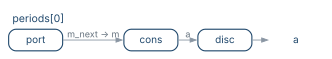

In [13]:
diagram_period(last, 0)

The period before the last is appended with the inter-period connector `{a: k}`: the savings that leave it become the capital at which next year's portfolio stage arrives. `accrete` writes the connector at `inter_connectors[0]`, derives the new period's joins, and checks the connector against the fields of the two periods it joins. The next cell names the result `two`.

In [14]:
two = accrete(last, period, {"a": "k"})

`diagram_trellis` draws each period as `diagram_period` does, in a frame labeled with its index $h$, and each inter-period connector as a wire labeled with its index and fields.

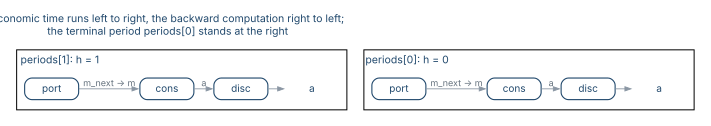

In [15]:
diagram_trellis(two)

`checkout.explore` shows the trellis `two` in [Google's Model Explorer](https://github.com/google-ai-edge/model-explorer), an interactive viewer in which each period is a frame holding its stages, each stage is a frame opened to its builders, and each builder opens on a click to the operations it holds; selecting an operation shows, in a side panel, its kernel, its method once one is bound, and the wires it reads and writes, each with its perch and its type. The drawing above is the picture saved with the lesson, since the view opens only when the lesson is run: the saved output of the next cell is the paths of the two files it writes into the folder `model-explorer` beside the lesson.

In [16]:
checkout.explore(two)

tutorials/getting-started/model-explorer/trellis.graph.json
tutorials/getting-started/model-explorer/trellis.edge-overlays.json


A **stage occurrence**, one use of a stage file at one position, is a copy of its own and records its position in its provenance, the record of where it came from; here the earlier period's portfolio stage:

In [17]:
two["periods"][1]["stages"]["port"].provenance["position"]

mappingproxy({'h': 1, 'key': 'port'})

## The recipe and the trellis file

A trellis may also be written as files. The recipe `spec.port-cons.yml` of the portfolio–consumption application names its trellis file and, for each stage key, the stage file and the three files that bind it; the trellis file `trellis.port-cons.yml` writes one period of those keys once with `repeat: 6` and one inter-period connector for every adjacent pair. The stage files are the application's own, written with the maximization alone, so the period is that of the two lessons of this model that follow. The three binding files are its [[calibration]], the values of its parameters; its [[methodization|methods]], the numerical method attached at each place; and its [[settings]], the numbers the methods read, such as grid sizes.

In [18]:
print(open("applications/cons-port/declaration/spec.port-cons.yml").read())
print(open("applications/cons-port/declaration/trellis.port-cons.yml").read())

# The recipe of the demonstration in the order portfolio first: the trellis file and each stage's file, by
# their paths from this folder, and for each stage the sources of its calibration, settings and methods.
# One calibration serves the three stages; each binds the parameters it declares.
trellis: trellis.port-cons.yml
stages:
  cons: {stage: stages/cons/cons.bl, calibration: {all: [calibration/portfolio]}, settings: {all: [settings/cons_wide]}, methods: {all: [methods/cons]}}
  disc: {stage: stages/disc/disc.bl, calibration: {all: [calibration/portfolio]}, methods: {all: [methods/disc]}}
  port: {stage: stages/port/port.bl, calibration: {all: [calibration/portfolio]}, settings: {all: [settings/port_wide]}, methods: {all: [methods/port]}}

!trellis
name: port_cons
# Portfolio first, the returns drawn at the beginning of the period: the share is chosen on capital,
# consumption follows on the resources the draws give, and discounting closes the period; the savings that
# leave each 

`load_recipe` reads the recipe, its trellis file and every file they name and returns the **syntactic trellis**, the model as written: a trellis with a **record** at each stage key in place of a stage, holding the stage file's text and the three mappings as data. Nothing is constructed.

In [19]:
syntactic = load_recipe("applications/cons-port/declaration", "spec.port-cons.yml")

The calibration in the record of the last period's discount stage is the whole mapping of `portfolio.yml`; the stage binds only the parameter it declares, $\beta$.

In [20]:
syntactic["periods"][0]["stages"]["disc"]["calibration"]

{'β': 0.96,
 'ρ': 6.0,
 'R': 1.02,
 'μ_Ψ': 0.028927,
 'σ_Ψ': 0.143486,
 'μ_θ': -0.01125,
 'σ_θ': 0.15,
 'ρ_ζ': 0.0}

`elaborate_trellis` constructs each distinct stage file once, places a copy at each position, and appends the periods with `accrete`, which checks their joins. The result, the **elaborated trellis**, holds a symbolic stage at every key; the next cell names it `elaborated`.

In [21]:
elaborated = elaborate_trellis(syntactic)

The trellis verbs `calibrate_trellis`, `methodize_trellis` and `configure_trellis` bind each stage occurrence to the mapping of their kind that its record holds; each returns a new trellis and leaves its argument unchanged. A stage bound in all three is [[specified_stage|specified]]. The next cell applies the three in that order and names the result `model`.

In [22]:
model = configure_trellis(methodize_trellis(calibrate_trellis(elaborated, syntactic), syntactic), syntactic)

The next cell shows the last period of `model`.

In [23]:
model["periods"][0]["stages"]

{'port': ElaboratedStage('port', specified),
 'cons': ElaboratedStage('cons', specified),
 'disc': ElaboratedStage('disc', specified)}

The trellis holds six periods and, for each adjacent pair, the inter-period connector `{disc.a: k}`, the savings after discounting as the next period's capital.

In [24]:
len(model["periods"]), model["inter_connectors"]

(6,
 [{'disc.a': 'k'},
  {'disc.a': 'k'},
  {'disc.a': 'k'},
  {'disc.a': 'k'},
  {'disc.a': 'k'}])

## A value that differs by period

An adjustment to a model is made in the syntactic trellis, and the verbs then bind what changed. Here the last period's discount factor is lowered from 0.96 to 0.9 in its record.

In [25]:
syntactic["periods"][0]["stages"]["disc"]["calibration"]["β"] = 0.9

Given the specified trellis and the adjusted syntactic trellis, `calibrate_trellis` binds anew each stage occurrence whose calibration changed in a parameter it declares, and copies the others. The next cell names the result `adjusted`.

In [26]:
adjusted = calibrate_trellis(model, syntactic)

`changed_positions` lists the positions `(h, key)` whose stage occurrence is a new version: the last period's discount stage alone.

In [27]:
changed_positions(model, adjusted)

[(0, 'disc')]

That stage holds the new value.

In [28]:
adjusted["periods"][0]["stages"]["disc"].par

name  set     value  describes
β     (0, 1)  0.9

The same stage in `model` keeps the value of the file.

In [29]:
model["periods"][0]["stages"]["disc"].par

name  set     value  describes
β     (0, 1)  0.96

A model kept in a **registry**, a folder of its stage, calibration, methods and settings files with a [[spec_factory|recipe]] naming the files of each stage, is read and bound by the same verbs; [the walkthrough of the Benhabib model](../models/benhabib-2019/the-factory-on-benhabib.ipynb) applies one.